---
title: "Series Solutions, Hermite and Laguerre Functions"
short_title: "Q-M2 Series Solutions & Special Functions"
numbering:
  heading_2: true
  equation: true
---

# Series Solutions, Hermite and Laguerre Functions

:::{tip} Where this sits in the plan
Math for the **harmonic oscillator** and the **hydrogen atom** (quantum topics 3 and 5). E&M E-M2 met Legendre polynomials the same way; here the method is the point: a power series that must terminate is what quantizes the energy.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Series solutions of ODEs (Frobenius) | 17 | 12 | 5 | 7 |
| Hermite and Laguerre functions | – | 12 | – | 18 |
| Gaussian integrals | 15 | 11 | – | 13 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [The Harmonic Oscillator](../qm/03-harmonic-oscillator.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Power-Series Solutions**

   (a) Solve $y'' + y = 0$ with $y = \sum a_nx^n$. Find the recursion and identify the two series.

   (b) Find the indicial equation for $xy'' + y' + xy = 0$ (Bessel's equation of order 0) at $x = 0$. What is unusual about its roots?

2. **The Hermite Equation and Quantization**

   The oscillator's series coefficients obey $a_{j+2} = \dfrac{2j + 1 - K}{(j + 1)(j + 2)}a_j$, with $K = 2E/\hbar\omega$.

   (a) What goes wrong if the series doesn't terminate?

   (b) What condition makes it terminate, and what energies does that give?

3. **Properties of Hermite Polynomials**

   (a) Starting from $H_2 = 4\xi^2 - 2$ and $H_3 = 8\xi^3 - 12\xi$, use $H_{n+1} = 2\xi H_n - 2nH_{n-1}$ to find $H_4$.

   (b) Without computing it, why is $\int H_1H_2\,e^{-\xi^2}\,d\xi = 0$?

4. **Laguerre Functions**

   Hydrogen's radial functions involve $L^{2\ell+1}_{n-\ell-1}$.

   (a) How many radial nodes do the $(n, \ell) = (2, 1)$ and $(3, 0)$ states have?

   (b) What is the weight function for orthogonality of $L^\alpha_k(\rho)$?

:::{dropdown} Answers
1. (a) $a_{n+2} = -\dfrac{a_n}{(n + 2)(n + 1)}$. The even series is $a_0\cos x$ and the odd series is $a_1\sin x$.

   (b) $s^2 = 0$: a repeated root. The second solution needs a logarithm.

2. (a) For large $j$, $a_{j+2}/a_j \approx 2/j$, so the series grows like $e^{\xi^2}$ and the wave function is not normalizable.

   (b) $K = 2n + 1$, so $E = \left(n + \tfrac12\right)\hbar\omega$.

3. (a) $H_4 = 2\xi H_3 - 6H_2 = 16\xi^4 - 48\xi^2 + 12$.

   (b) $H_1H_2e^{-\xi^2}$ is odd, since $H_n$ has parity $(-1)^n$.

4. (a) The number of radial nodes is $n - \ell - 1$: 0 for $(2, 1)$ and 2 for $(3, 0)$.

   (b) $\rho^\alpha e^{-\rho}$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Power-Series Solutions

When a linear ODE has non-constant coefficients, try $y = \sum_{j=0}^\infty a_jx^j$. Substituting turns the ODE into a **recursion relation** for the coefficients.

::::{prf:example} A warm-up with a known answer
:label: ex-series-warmup

Solve $y'' + y = 0$ by series.

:::{dropdown} Solution
$y'' = \sum_j(j+2)(j+1)a_{j+2}x^j$. Matching powers of $x$ in $y'' + y = 0$:

$$
a_{j+2} = -\frac{a_j}{(j+2)(j+1)} .
$$

Starting from $a_0$ (with $a_1 = 0$): $a_2 = -a_0/2$, $a_4 = a_0/24$, ..., the series for $a_0\cos x$. Starting from $a_1$ gives $a_1\sin x$. A second-order equation's recursion links $a_{j+2}$ to $a_j$, so even and odd coefficients form two independent solutions.
:::
::::

**Frobenius' extension.** At a point where the coefficients blow up (a *regular singular point*, such as $r = 0$ in a radial equation), try $y = x^s\sum a_jx^j$ with $a_0\ne0$. The lowest power gives the **indicial equation** for $s$. For the radial equation in quantum topic 5 it gives $s = \ell + 1$ or $s = -\ell$, and only the first is finite at the origin.

## The Hermite Equation and Quantization

The harmonic oscillator, $-\frac{\hbar^2}{2m}\psi'' + \frac12m\omega^2x^2\psi = E\psi$, in the dimensionless variable $\xi = \sqrt{m\omega/\hbar}\,x$ with $K = 2E/\hbar\omega$, becomes

$$
\psi'' = (\xi^2 - K)\psi .
$$ (eq-ho-dimensionless)

For large $\xi$ the $\xi^2$ term dominates and $\psi\sim e^{-\xi^2/2}$ (the growing $e^{+\xi^2/2}$ is not normalizable). Peel that off: $\psi = h(\xi)e^{-\xi^2/2}$. Then $h$ satisfies **Hermite's equation**,

$$
h'' - 2\xi h' + (K - 1)h = 0 ,
$$ (eq-hermite-ode)

and the series method gives

$$
a_{j+2} = \frac{2j + 1 - K}{(j+1)(j+2)}\,a_j .
$$ (eq-hermite-recursion)

For large $j$, $a_{j+2}\approx(2/j)a_j$, which is the coefficient pattern of $e^{\xi^2}$. An infinite series would make $\psi\sim e^{\xi^2}e^{-\xi^2/2} = e^{+\xi^2/2}$: not normalizable. **The series must stop.** It stops at $j = n$ only if $K = 2n + 1$, so

$$
E_n = \left(n + \tfrac12\right)\hbar\omega,\qquad n = 0, 1, 2, \ldots
$$ (eq-ho-energies)

The energy is quantized because of a boundary condition at infinity, enforced through a recursion. The polynomials that result (normalized so the leading coefficient is $2^n$) are the **Hermite polynomials** $H_n(\xi)$.

In [2]:
# Build H_n from the recursion and compare with SymPy's hermite()
xi = sp.symbols("xi")
def from_recursion(n):
    K = 2 * n + 1
    a = {n % 2: sp.Integer(1)}
    for j in range(n % 2, n - 1, 2):
        a[j + 2] = sp.Rational(2 * j + 1 - K, (j + 1) * (j + 2)) * a[j]
    poly = sum(c * xi**j for j, c in a.items())
    return sp.expand(poly * 2**n / a[n])          # leading coefficient 2^n
for n in range(5):
    display(Math(rf"H_{n}(\xi) = " + sp.latex(from_recursion(n)) + r"\quad" + (r"\checkmark" if sp.expand(from_recursion(n) - sp.hermite(n, xi)) == 0 else r"\times")))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

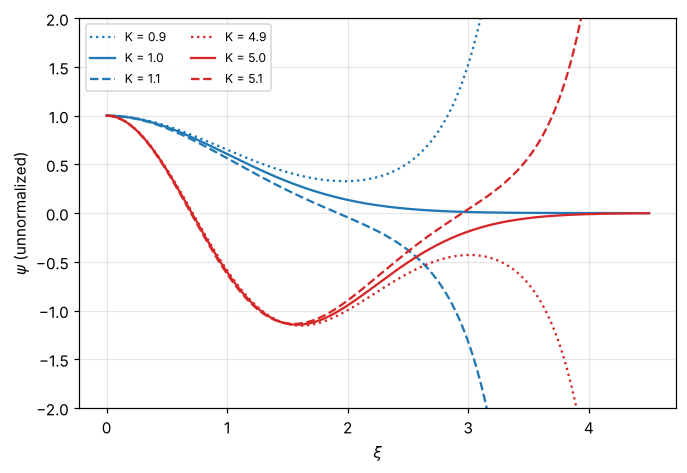

In [3]:
#| label: fig-shooting-ho
#| caption: "Integrating ψ'' = (ξ² − K)ψ outward from ξ = 0 with even initial conditions. Only at K = 1 and K = 5 (the n = 0 and n = 2 levels) does ψ decay; slightly off, the e^(+ξ²/2) solution takes over and ψ blows up. This is the same quantization the recursion gives, seen numerically."
def shoot(K, xmax=4.5):
    sol = solve_ivp(lambda t, y: [y[1], (t**2 - K) * y[0]], (0, xmax), [1.0, 0.0], max_step=0.01)
    return sol.t, sol.y[0]
fig, ax = plt.subplots()
for K, col, ls in [(0.9, "tab:blue", ":"), (1.0, "tab:blue", "-"), (1.1, "tab:blue", "--"),
                   (4.9, "tab:red", ":"), (5.0, "tab:red", "-"), (5.1, "tab:red", "--")]:
    t, y = shoot(K); ax.plot(t, y, color=col, ls=ls, label=f"K = {K}")
ax.set_ylim(-2, 2); ax.set_xlabel("$\\xi$"); ax.set_ylabel("$\\psi$ (unnormalized)"); ax.legend(ncol=2, fontsize=8); plt.show()

## Properties of Hermite Polynomials

Three equivalent definitions, each useful for something:

$$
H_n(\xi) = (-1)^ne^{\xi^2}\frac{d^n}{d\xi^n}e^{-\xi^2}\quad\text{(Rodrigues)},\qquad
e^{2\xi t - t^2} = \sum_{n=0}^\infty H_n(\xi)\frac{t^n}{n!}\quad\text{(generating function)},
$$ (eq-hermite-defs)

and the recursion $H_{n+1} = 2\xi H_n - 2nH_{n-1}$, which is the fast, stable way to compute them.

**Orthogonality.** With the weight $e^{-\xi^2}$,

$$
\int_{-\infty}^\infty H_m(\xi)H_n(\xi)e^{-\xi^2}\,d\xi = \sqrt\pi\,2^nn!\,\delta_{mn} ,
$$ (eq-hermite-orthogonality)

so the normalized oscillator eigenfunctions are

$$
\psi_n(x) = \left(\frac{m\omega}{\pi\hbar}\right)^{1/4}\frac{1}{\sqrt{2^nn!}}H_n(\xi)\,e^{-\xi^2/2} .
$$ (eq-ho-eigenfunctions)

Orthogonality is not luck: the $\psi_n$ are eigenfunctions of a Hermitian operator with different eigenvalues (Q-M3), the same reason Legendre polynomials are orthogonal (E-M2).

In [4]:
# Check orthogonality numerically for the first few, with SymPy exact integrals
M = sp.Matrix(4, 4, lambda m, n: sp.integrate(sp.hermite(m, xi) * sp.hermite(n, xi) * sp.exp(-xi**2), (xi, -sp.oo, sp.oo)))
display(Math(r"\left[\int H_mH_ne^{-\xi^2}d\xi\right]_{m,n=0..3} = " + sp.latex(M)))

<IPython.core.display.Math object>

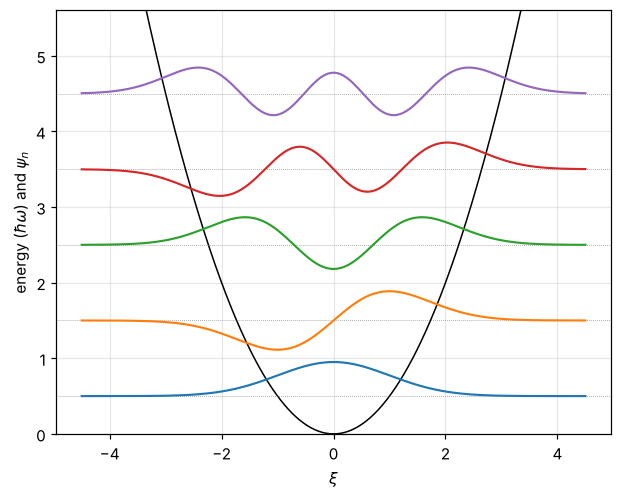

In [5]:
#| label: fig-hermite-functions
#| caption: "The first five oscillator eigenfunctions ψ_n(ξ), each drawn at height n + ½ (its energy in units of ħω) inside the potential ξ²/2. ψ_n has n nodes, alternates between even and odd, and leaks a little past the classical turning points where the parabola meets its energy line."
from scipy.special import eval_hermite, factorial
X = np.linspace(-4.5, 4.5, 600)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(X, X**2 / 2, color="k", lw=1)
for n in range(5):
    psi_n = np.pi**-0.25 / np.sqrt(2.0**n * factorial(n)) * eval_hermite(n, X) * np.exp(-X**2 / 2)
    E = n + 0.5
    ax.axhline(E, color="gray", lw=0.5, ls=":")
    ax.plot(X, E + 0.6 * psi_n, lw=1.4)
ax.set_ylim(0, 5.6); ax.set_xlabel("$\\xi$"); ax.set_ylabel("energy ($\\hbar\\omega$) and $\\psi_n$"); plt.show()

## Laguerre Functions

The hydrogen radial equation (quantum topic 5), after peeling off its behavior near $r = 0$ ($\sim r^{\ell+1}$) and at infinity ($\sim e^{-r/na}$), becomes the **associated Laguerre equation**

$$
\rho\,v'' + (2\ell + 2 - \rho)\,v' + (n - \ell - 1)\,v = 0 ,
$$ (eq-laguerre-ode)

with $\rho = 2r/na$. Its series solution has

$$
c_{j+1} = \frac{j + \ell + 1 - n}{(j+1)(j + 2\ell + 2)}\,c_j ,
$$ (eq-laguerre-recursion)

and the same argument applies: an unterminated series grows like $e^{\rho}$, ruining normalizability, so $n$ must be an integer with $n\ge\ell + 1$. The terminating solutions are the associated Laguerre polynomials $L^{2\ell+1}_{n-\ell-1}(\rho)$, and the energy $E_n = -13.6\text{ eV}/n^2$ follows from the value of $n$ that terminates the series.

They are orthogonal with weight $\rho^\alpha e^{-\rho}$ on $[0, \infty)$:

$$
\int_0^\infty L^\alpha_mL^\alpha_n\,\rho^\alpha e^{-\rho}\,d\rho = \frac{(n + \alpha)!}{n!}\,\delta_{mn} .
$$ (eq-laguerre-orthogonality)

(Conventions for Laguerre polynomials differ by factors of $n!$ and signs between books; the code uses SciPy's, which matches most modern texts.)

In [6]:
r_ = sp.symbols("rho", positive=True)
al = 3
M2 = sp.Matrix(3, 3, lambda m, n: sp.integrate(sp.assoc_laguerre(m, al, r_) * sp.assoc_laguerre(n, al, r_) * r_**al * sp.exp(-r_), (r_, 0, sp.oo)))
display(Math(rf"\left[\int_0^\infty L^{{{al}}}_mL^{{{al}}}_n\rho^{{{al}}}e^{{-\rho}}d\rho\right]_{{m,n=0..2}} = " + sp.latex(M2)))

<IPython.core.display.Math object>

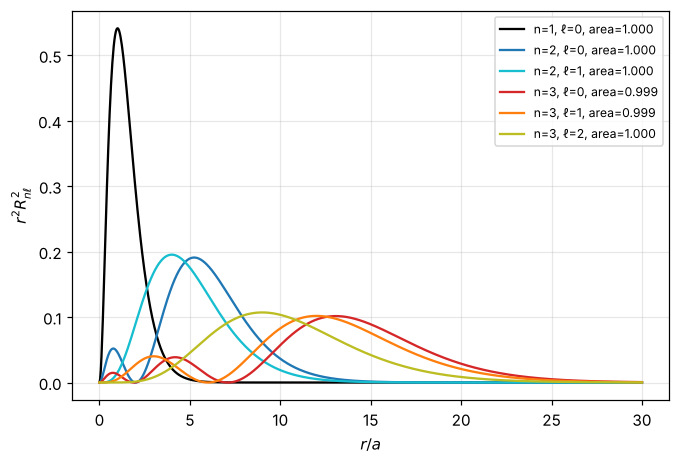

In [7]:
#| label: fig-laguerre-radial
#| caption: "Hydrogen radial probability densities r²R²(r) built from associated Laguerre polynomials, for (n, ℓ) = (1,0), (2,0), (2,1), (3,0), (3,1), (3,2), with r in Bohr radii. Each has n − ℓ − 1 radial nodes; states with ℓ = n − 1 have none and peak at r = n²a."
from scipy.special import eval_genlaguerre
r = np.linspace(0, 30, 800)
def R_nl(n, l, r):
    rho = 2 * r / n
    norm = np.sqrt((2 / n)**3 * factorial(n - l - 1) / (2 * n * factorial(n + l)))
    return norm * rho**l * np.exp(-rho / 2) * eval_genlaguerre(n - l - 1, 2 * l + 1, rho)
fig, ax = plt.subplots()
for (n, l), col in zip([(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2)],
                       ["k", "tab:blue", "tab:cyan", "tab:red", "tab:orange", "tab:olive"]):
    P = r**2 * R_nl(n, l, r)**2
    ax.plot(r, P, color=col, label=f"n={n}, ℓ={l}, area={np.trapezoid(P, r):.3f}")
ax.set_xlabel("$r/a$"); ax.set_ylabel("$r^2R_{n\\ell}^2$"); ax.legend(fontsize=8); plt.show()

### Exercises

1. Use the recursion {eq}`eq-hermite-recursion` to find $H_5(\xi)$, and check it against $H_{n+1} = 2\xi H_n - 2nH_{n-1}$.
2. Derive $H_0$ through $H_3$ from the generating function by expanding $e^{2\xi t - t^2}$ to order $t^3$.
3. Show that $\psi_1$ and $\psi_2$ of the oscillator are orthogonal without using {eq}`eq-hermite-orthogonality`. Which property makes one case trivial?
4. Find the indicial equation for $x^2y'' + xy' + (x^2 - \nu^2)y = 0$ (Bessel's equation) at $x = 0$.
5. For hydrogen with $n = 2$, $\ell = 0$, find where the radial node is, using $L^1_1(\rho) = 2 - \rho$.

:::{dropdown} Hints
1. Start with $a_1 = 1$ and $K = 11$, then scale so the leading coefficient is $2^5 = 32$.
2. Multiply out $e^{2\xi t}e^{-t^2}$ and collect powers of $t$; $H_n$ is $n!$ times the coefficient of $t^n$.
3. Parity.
4. Substitute $y = x^s\sum a_jx^j$ and keep the lowest power.
5. $\rho = 2r/na = r/a$ for $n = 2$.
:::

:::{dropdown} Answers
1. $H_5 = 32\xi^5 - 160\xi^3 + 120\xi$.
2. $H_0 = 1$, $H_1 = 2\xi$, $H_2 = 4\xi^2 - 2$, $H_3 = 8\xi^3 - 12\xi$.
3. $\psi_1$ is odd and $\psi_2$ is even, so their product is odd and integrates to zero over a symmetric interval.
4. $s^2 - \nu^2 = 0$, so $s = \pm\nu$.
5. $L^1_1 = 0$ at $\rho = 2$, i.e. $r = 2a$.
:::

## Summary

- Series solutions turn an ODE into a recursion; Frobenius' $x^s$ handles regular singular points.
- If the series does not terminate it grows like $e^{\xi^2}$ (Hermite) or $e^\rho$ (Laguerre), destroying normalizability. Requiring termination quantizes the energy.
- $H_n$: Rodrigues formula, generating function $e^{2\xi t - t^2}$, recursion $H_{n+1} = 2\xi H_n - 2nH_{n-1}$, orthogonal with weight $e^{-\xi^2}$.
- Associated Laguerre $L^{2\ell+1}_{n-\ell-1}$ build hydrogen's radial functions; orthogonal with weight $\rho^\alpha e^{-\rho}$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.